# Ejemplo 1 – Red neuronal de reconocimiento de patrones (clasificación)
**Problema industrial:** clasificación automática de granos de frijol seco en 7 variedades
a partir de 16 características geométricas obtenidas por visión por computadora
(sistema de selección de semillas certificadas).

**Dataset:** *Dry Bean Dataset* – UCI Machine Learning Repository (Koklu y Ozkan, 2020),
13 611 granos, 16 atributos, 7 clases. https://archive.ics.uci.edu/dataset/602/dry+bean+dataset

**Red:** perceptrón multicapa (MLP) con salida *softmax* y entropía cruzada, Keras/TensorFlow.

Alumno: Alessandro Díaz – Sistemas Inteligentes, UAC.

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/alessdi/PracticaMachineLearning/blob/main/notebooks/01_clasificacion_drybean.ipynb)

Ejecutar con **Entorno de ejecución → Ejecutar todas**. Los datos se descargan automáticamente.

In [1]:
import io, os, sys, time, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib
if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

SEMILLA = 42
keras.utils.set_random_seed(SEMILLA)
RESULTADOS = "../resultados" if os.path.isdir("../data") else "resultados"
os.makedirs(RESULTADOS, exist_ok=True)
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## 1. Carga del dataset (desde la copia local, la fuente oficial UCI o el repositorio)

In [2]:
URL_UCI = "https://archive.ics.uci.edu/static/public/602/dry+bean+dataset.zip"
URL_REPO = "https://raw.githubusercontent.com/alessdi/PracticaMachineLearning/main/data/Dry_Bean_Dataset.csv"

def cargar_drybean():
    for ruta in ("data/Dry_Bean_Dataset.csv", "../data/Dry_Bean_Dataset.csv"):
        if os.path.exists(ruta):
            return pd.read_csv(ruta), ruta
    try:
        with urllib.request.urlopen(URL_UCI, timeout=60) as r:
            z = zipfile.ZipFile(io.BytesIO(r.read()))
        return pd.read_excel(z.open("DryBeanDataset/Dry_Bean_Dataset.xlsx")), URL_UCI
    except Exception as e:
        print("UCI no disponible:", e)
        return pd.read_csv(URL_REPO), URL_REPO

df, origen = cargar_drybean()
print(f"Datos cargados de: {origen}")
print("Forma:", df.shape)
print(df["Class"].value_counts().to_string())
df.head()

Datos cargados de: ../data/Dry_Bean_Dataset.csv
Forma: (13611, 17)
Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


## 2. Preprocesamiento: división estratificada 70/15/15 y estandarización

In [3]:
X = df.drop(columns="Class").values.astype("float32")
codificador = LabelEncoder()
y = codificador.fit_transform(df["Class"])
CLASES = list(codificador.classes_)
N_CLASES = len(CLASES)

X_ent, X_tmp, y_ent, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEMILLA)
X_val, X_pru, y_val, y_pru = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEMILLA)

escalador = StandardScaler().fit(X_ent)          # solo con datos de entrenamiento
X_ent, X_val, X_pru = (escalador.transform(a) for a in (X_ent, X_val, X_pru))
print(f"Entrenamiento: {len(X_ent)}  Validación: {len(X_val)}  Prueba: {len(X_pru)}")

Entrenamiento: 9527  Validación: 2042  Prueba: 2042


## 3. Modelo y ajuste de parámetros
Se comparan varias arquitecturas y tasas de aprendizaje; se elige la de mayor exactitud de validación.

In [4]:
def crear_modelo(capas, tasa, dropout):
    modelo = keras.Sequential([keras.Input(shape=(X_ent.shape[1],))])
    for n in capas:
        modelo.add(keras.layers.Dense(n, activation="relu"))
        modelo.add(keras.layers.BatchNormalization())
        modelo.add(keras.layers.Dropout(dropout))
    modelo.add(keras.layers.Dense(N_CLASES, activation="softmax"))
    modelo.compile(optimizer=keras.optimizers.Adam(tasa),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return modelo

def entrenar(capas, tasa, dropout, epocas=200, verbose=0):
    keras.utils.set_random_seed(SEMILLA)
    modelo = crear_modelo(capas, tasa, dropout)
    cb = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True),
          keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=8, min_lr=1e-5)]
    hist = modelo.fit(X_ent, y_ent, validation_data=(X_val, y_val), epochs=epocas,
                      batch_size=64, callbacks=cb, verbose=verbose)
    return modelo, hist

REJILLA = [((32,), 1e-3, 0.1), ((64, 32), 1e-3, 0.2), ((128, 64), 1e-3, 0.2),
           ((128, 64, 32), 1e-3, 0.3), ((64, 32), 3e-3, 0.2)]
resultados = []
for capas, tasa, dropout in REJILLA:
    t0 = time.time()
    modelo, hist = entrenar(capas, tasa, dropout)
    acc_val = modelo.evaluate(X_val, y_val, verbose=0)[1]
    resultados.append({"capas ocultas": str(capas), "tasa": tasa, "dropout": dropout,
                       "épocas": len(hist.history["loss"]), "exactitud val %": round(100 * acc_val, 2),
                       "tiempo s": round(time.time() - t0, 1)})
    print(resultados[-1])
tabla_ajuste = pd.DataFrame(resultados)
tabla_ajuste.to_csv(f"{RESULTADOS}/clasificacion_ajuste.csv", index=False)
print(tabla_ajuste.to_string(index=False))

{'capas ocultas': '(32,)', 'tasa': 0.001, 'dropout': 0.1, 'épocas': 50, 'exactitud val %': 93.0, 'tiempo s': 7.3}


{'capas ocultas': '(64, 32)', 'tasa': 0.001, 'dropout': 0.2, 'épocas': 61, 'exactitud val %': 93.1, 'tiempo s': 11.1}


{'capas ocultas': '(128, 64)', 'tasa': 0.001, 'dropout': 0.2, 'épocas': 64, 'exactitud val %': 93.14, 'tiempo s': 13.5}


{'capas ocultas': '(128, 64, 32)', 'tasa': 0.001, 'dropout': 0.3, 'épocas': 62, 'exactitud val %': 93.14, 'tiempo s': 21.2}


{'capas ocultas': '(64, 32)', 'tasa': 0.003, 'dropout': 0.2, 'épocas': 56, 'exactitud val %': 93.0, 'tiempo s': 13.8}
capas ocultas  tasa  dropout  épocas  exactitud val %  tiempo s
        (32,) 0.001      0.1      50            93.00       7.3
     (64, 32) 0.001      0.2      61            93.10      11.1
    (128, 64) 0.001      0.2      64            93.14      13.5
(128, 64, 32) 0.001      0.3      62            93.14      21.2
     (64, 32) 0.003      0.2      56            93.00      13.8


## 4. Entrenamiento final con la mejor configuración

In [5]:
mejor = tabla_ajuste.loc[tabla_ajuste["exactitud val %"].idxmax()]
capas = tuple(int(c) for c in mejor["capas ocultas"].strip("(),").split(",") if c.strip())
print(f"Mejor configuración: capas={capas}, tasa={mejor['tasa']}, dropout={mejor['dropout']}")
modelo, hist = entrenar(capas, float(mejor["tasa"]), float(mejor["dropout"]), verbose=2)
modelo.summary()
modelo.save(f"{RESULTADOS}/modelo_drybean.keras")

Mejor configuración: capas=(128, 64), tasa=0.001, dropout=0.2
Epoch 1/200


149/149 - 1s - 7ms/step - accuracy: 0.8332 - loss: 0.4949 - val_accuracy: 0.9172 - val_loss: 0.4599 - learning_rate: 0.0010


Epoch 2/200


149/149 - 0s - 2ms/step - accuracy: 0.9061 - loss: 0.2722 - val_accuracy: 0.9295 - val_loss: 0.2330 - learning_rate: 0.0010


Epoch 3/200


...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_15 (Dense)                │ (None, 128)            │         2,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,199 (133.59 KB)

 Trainable params: 11,271 (44.03 KB)

 Non-trainable params: 384 (1.50 KB)

 Optimizer params: 22,544 (88.07 KB)

## 5. Evaluación en el conjunto de prueba

Exactitud  entrenamiento: 94.34 %  validación: 93.14 %  prueba: 92.70 %
              precision    recall  f1-score   support

    BARBUNYA      0.943     0.915     0.929       199
      BOMBAY      1.000     1.000     1.000        78
        CALI      0.934     0.931     0.933       245
    DERMASON      0.921     0.921     0.921       532
       HOROZ      0.952     0.969     0.961       289
       SEKER      0.954     0.951     0.952       304
        SIRA      0.869     0.876     0.873       395

    accuracy                          0.927      2042
   macro avg      0.939     0.937     0.938      2042
weighted avg      0.927     0.927     0.927      2042



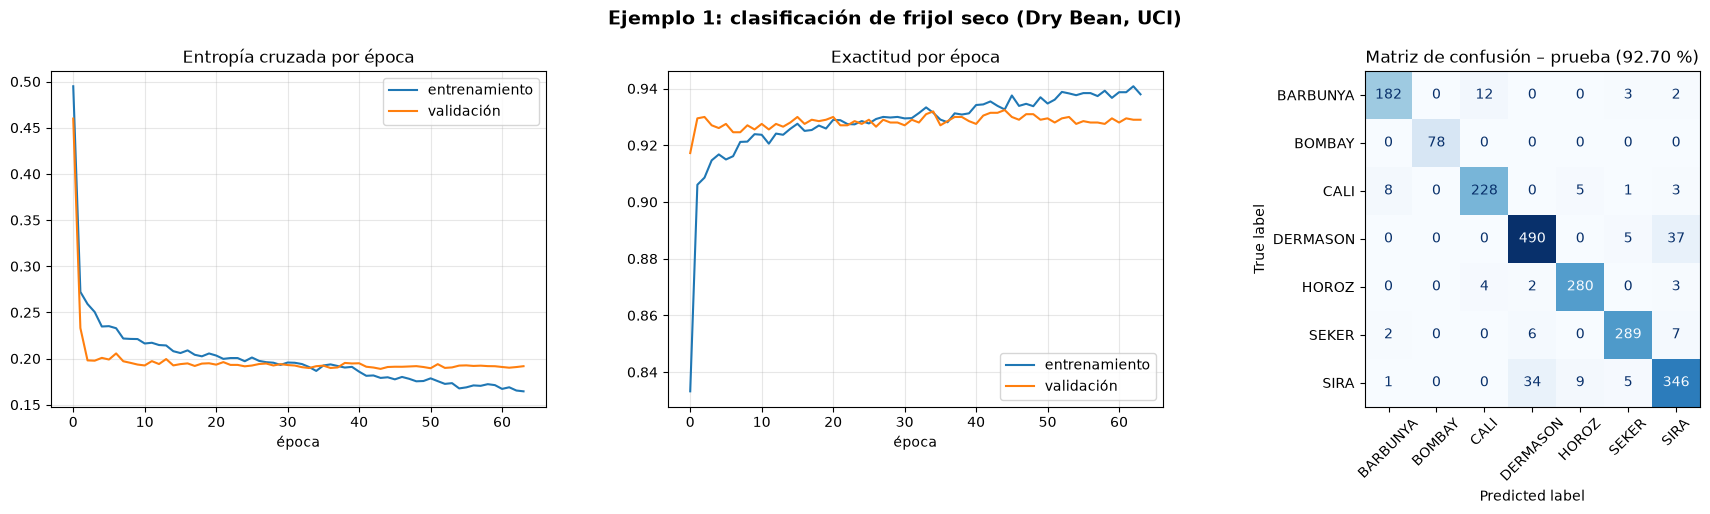

In [6]:
y_pred = modelo.predict(X_pru, verbose=0).argmax(axis=1)
acc_ent = accuracy_score(y_ent, modelo.predict(X_ent, verbose=0).argmax(axis=1))
acc_val = accuracy_score(y_val, modelo.predict(X_val, verbose=0).argmax(axis=1))
acc_pru = accuracy_score(y_pru, y_pred)
print(f"Exactitud  entrenamiento: {100*acc_ent:.2f} %  validación: {100*acc_val:.2f} %  prueba: {100*acc_pru:.2f} %")
print(classification_report(y_pru, y_pred, target_names=CLASES, digits=3))

fig, ax = plt.subplots(1, 3, figsize=(18, 5.2))
ax[0].plot(hist.history["loss"], label="entrenamiento"); ax[0].plot(hist.history["val_loss"], label="validación")
ax[0].set_title("Entropía cruzada por época"); ax[0].set_xlabel("época"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(hist.history["accuracy"], label="entrenamiento"); ax[1].plot(hist.history["val_accuracy"], label="validación")
ax[1].set_title("Exactitud por época"); ax[1].set_xlabel("época"); ax[1].legend(); ax[1].grid(alpha=.3)
ConfusionMatrixDisplay(confusion_matrix(y_pru, y_pred), display_labels=CLASES).plot(
    ax=ax[2], cmap="Blues", colorbar=False, xticks_rotation=45)
ax[2].set_title(f"Matriz de confusión – prueba ({100*acc_pru:.2f} %)")
fig.suptitle("Ejemplo 1: clasificación de frijol seco (Dry Bean, UCI)", fontsize=14, weight="bold")
fig.tight_layout(); fig.savefig(f"{RESULTADOS}/clasificacion_drybean.png", dpi=130); plt.show()

## 6. Uso del modelo: clasificar granos nuevos

In [7]:
def clasificar_grano(caracteristicas):
    """caracteristicas: lista con las 16 medidas geométricas en el orden del dataset."""
    x = escalador.transform(np.array(caracteristicas, dtype="float32").reshape(1, -1))
    p = modelo.predict(x, verbose=0)[0]
    return CLASES[p.argmax()], p.max()

muestras = df.drop(columns="Class").sample(5, random_state=7)
for i, fila in muestras.iterrows():
    clase, prob = clasificar_grano(fila.values)
    print(f"Grano {i:5d}: real = {df.loc[i, 'Class']:9s} -> red = {clase:9s} (p = {prob:.3f})")

Grano  3628: real = BOMBAY    -> red = BOMBAY    (p = 1.000)
Grano  5586: real = HOROZ     -> red = HOROZ     (p = 0.999)
Grano  6749: real = HOROZ     -> red = HOROZ     (p = 0.987)
Grano  4071: real = CALI      -> red = CALI      (p = 0.584)
Grano 11683: real = DERMASON  -> red = DERMASON  (p = 0.981)
